In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from plotting import *
from HeteroBilayer import HeteroBilayer
import utils
import analytic_metric

In [3]:
plt.rcParams.update({
    'figure.figsize': (7, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': False,   # remove top/right borders
    'axes.spines.right': False,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

# Honeycomb lattice

### Shifting Wannier functions

In [5]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=40, V=6.6, n_shells=8)

Norm Wannier A:  0.9994238356456546
Norm Wannier B:  0.9991181163339656


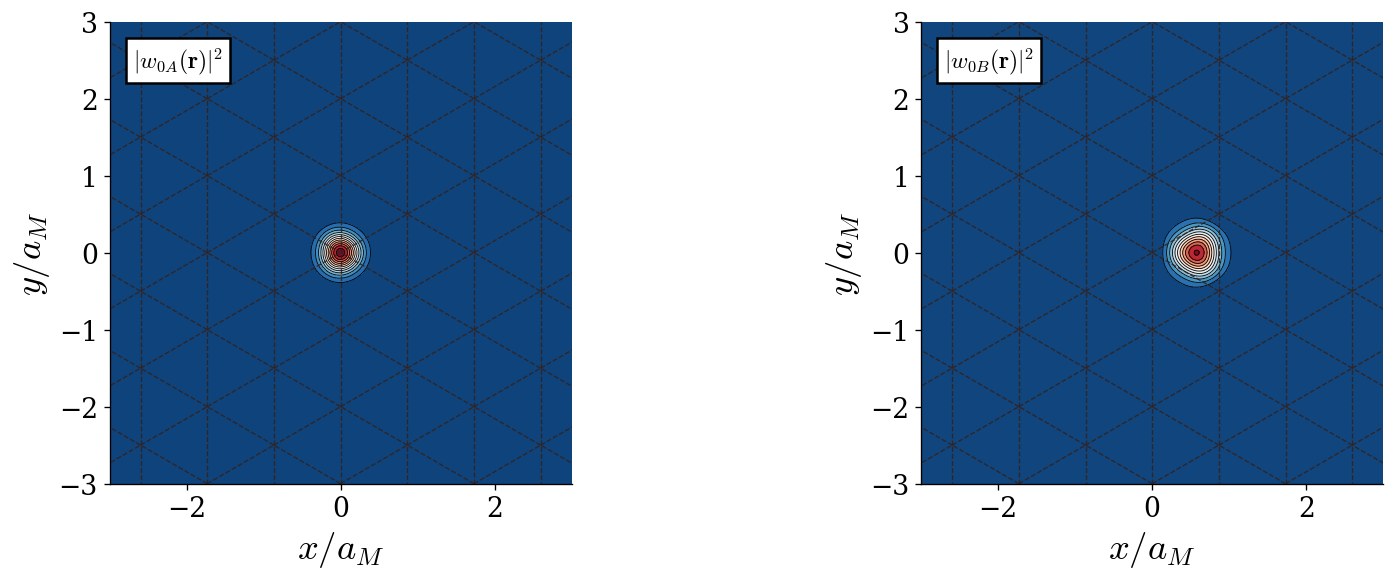

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
scale = 3.0
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

## Trial functions centers
RA = np.zeros(2)
RB = (2 * sys.a1 - sys.a2) / 3
##

Rshift = np.zeros(2)
wanniers = sys.wannier_function(X, Y, trial_centers=np.array([RA, RB]), R0=Rshift, bands=(-2, -1))
wannierA = wanniers[0, :, :]
wannierB = wanniers[1, :, :]
normA = sys.integrate_wannier(lambda x, y: 1.0, wannierA, X, Y)
normB = sys.integrate_wannier(lambda x, y: 1.0, wannierB, X, Y)
print("Norm Wannier A: ", normA)
print("Norm Wannier B: ", normB)

plot_wannier_function(sys, ax, X, Y, trial_centers=np.array([RA, RB]), R0=Rshift, bands=(-2, -1), cmap='RdBu_r')

Norm Wannier A:  0.999054146833444
Norm Wannier B:  0.9991836808214061


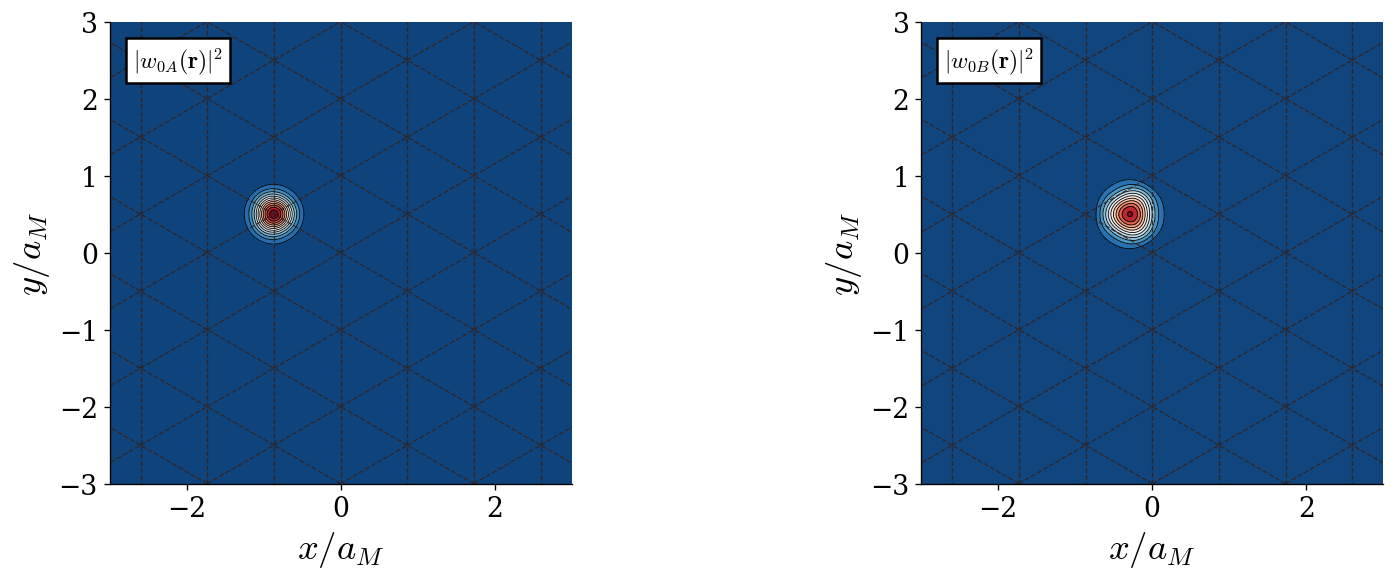

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
scale = 3.0
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

## Trial functions centers
RA = np.zeros(2)
RB = (2 * sys.a1 - sys.a2) / 3
##

Rshift = sys.a2 - sys.a1
wanniers = sys.wannier_function(X, Y, trial_centers=np.array([RA, RB]), R0=Rshift, bands=(-2, -1))
wannierA = wanniers[0, :, :]
wannierB = wanniers[1, :, :]
normA = sys.integrate_wannier(lambda x, y: 1.0, wannierA, X, Y)
normB = sys.integrate_wannier(lambda x, y: 1.0, wannierB, X, Y)
print("Norm Wannier A: ", normA)
print("Norm Wannier B: ", normB)

plot_wannier_function(sys, ax, X, Y, trial_centers=np.array([RA, RB]), R0=Rshift, bands=(-2, -1), cmap='RdBu_r')

### Hopping integrals

In [8]:
sys = HeteroBilayer(psi_deg=40)
thetas = np.linspace(0.5, 3.0, 10)

onsiteA = []
onsiteA_kspace = []
onsiteB = []
onsiteB_kspace = []

tAB = []
tAB_kspace = []
tAA = []
tAA_kspace = []
tBB = []
tBB_kspace = []

for th in tqdm(thetas):
    sys.theta_deg = th

    hoppingsA = sys.hopping_2band(orders=[0, 1], sublattice1="A", sublattice2="A")
    hoppingsB = sys.hopping_2band(orders=[0, 1], sublattice1="B", sublattice2="B")
    hoppingsA_kspace = sys.hopping_2band_kspace(orders=[0, 1], sublattice1="A", sublattice2="A")
    hoppingsB_kspace = sys.hopping_2band_kspace(orders=[0, 1], sublattice1="B", sublattice2="B")
    
    onsiteA.append(hoppingsA[0])
    onsiteB.append(hoppingsB[0])
    onsiteA_kspace.append(hoppingsA_kspace[0])
    onsiteB_kspace.append(hoppingsB_kspace[0])

    tAA.append(hoppingsA[1])
    tAA_kspace.append(hoppingsA_kspace[1])
    tBB.append(hoppingsB[1])
    tBB_kspace.append(hoppingsB_kspace[1])

    hoppingsAB = sys.hopping_2band(orders=[0], sublattice1="A", sublattice2="B")
    tAB.append(hoppingsAB[0])
    hoppingsAB_kspace = sys.hopping_2band_kspace(orders=[0], sublattice1="A", sublattice2="B")
    tAB_kspace.append(hoppingsAB_kspace[0])

100%|██████████| 10/10 [11:37<00:00, 69.71s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


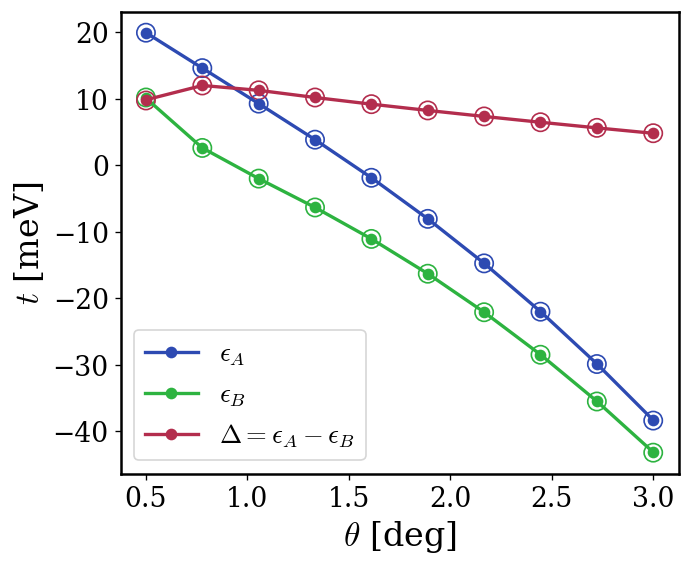

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, onsiteA, marker="o", label=r"$\epsilon_{A}$", color=cols[0])
ax.scatter(thetas, onsiteA_kspace, marker="o", edgecolors=cols[0], facecolors="none", s=120)
ax.plot(thetas, onsiteB, marker="o", label=r"$\epsilon_{B}$", color=cols[1])
ax.scatter(thetas, onsiteB_kspace, marker="o", edgecolors=cols[1], facecolors="none", s=120)

delta = np.array(onsiteA) - np.array(onsiteB)
delta_kspace = np.array(onsiteA_kspace) - np.array(onsiteB_kspace)

ax.plot(thetas, delta, marker="o", label=r"$\Delta=\epsilon_A - \epsilon_B$", color=cols[2])
ax.scatter(thetas, delta_kspace, marker="o", edgecolors=cols[2], facecolors="none", s=120)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

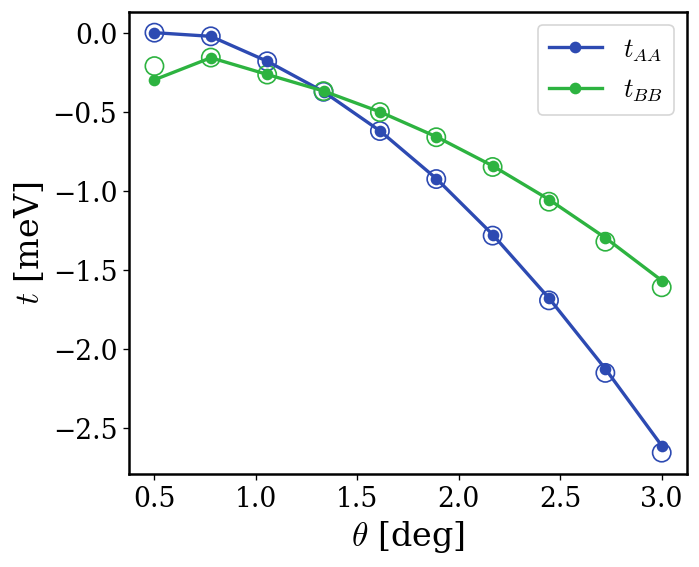

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, tAA, marker="o", label=r"$t_{AA}$", color=cols[0])
ax.scatter(thetas, tAA_kspace, marker="o", edgecolors=cols[0], facecolors="none", s=120)
ax.plot(thetas, tBB, marker="o", label=r"$t_{BB}$", color=cols[1])
ax.scatter(thetas, tBB_kspace, marker="o", edgecolors=cols[1], facecolors="none", s=120)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

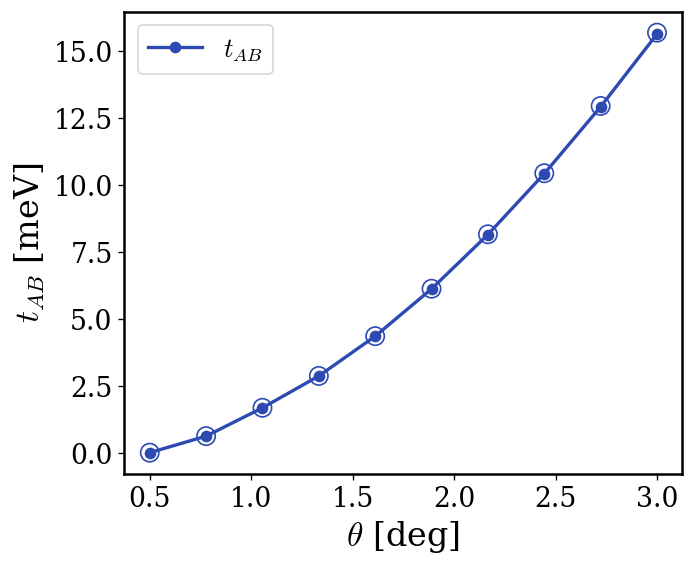

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, tAB, marker="o", label=r"$t_{AB}$", color=cols[0])
ax.scatter(thetas, tAB_kspace, marker="o", edgecolors=cols[0], facecolors="none", s=120)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t_{AB}$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Coulomb interactions

In [12]:
thetas = np.linspace(0.5, 3.0, 10)
UA = []
UB = []

for th in tqdm(thetas):
    sys.theta_deg = th

    interactionA = sys.interaction_2band(orders=[0], sublattice1="A", sublattice2="A")
    interactionB = sys.interaction_2band(orders=[0], sublattice1="B", sublattice2="B")

    # Coulomb matrix elements in eV
    UA.append(sys.epsilon * interactionA[0] / 1000)
    UB.append(sys.epsilon * interactionB[0] / 1000)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [02:31<00:00, 15.12s/it]


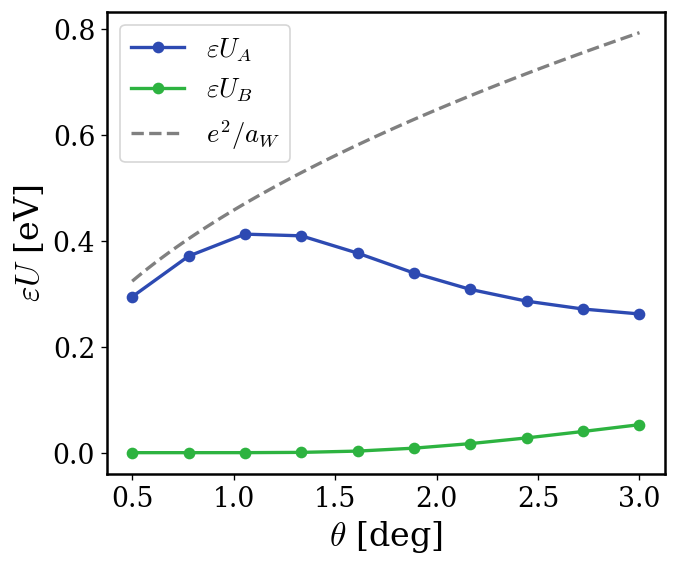

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, UA, marker="o", label=r"$\varepsilon U_A$", color=cols[0])
ax.plot(thetas, UB, marker="o", label=r"$\varepsilon U_B$", color=cols[1])

tt = np.linspace(0.5, 3.0, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))
ax.plot(tt, sys.E_SQUARED / (utils.spread_harmonic_approx(aMs, sys.V, sys.psi) * 1000),
       color="gray", linestyle="--", label=r"$e^2/a_W$", linewidth=2)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon U$ [eV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Exchange interaction

In [15]:
thetas = np.linspace(0.5, 3.0, 10)
X = []

for th in tqdm(thetas):
    sys.theta_deg = th

    interactions = sys.exchange_2band(orders=[1], sublattice1="A", sublattice2="A")

    # Coulomb matrix elements in meV
    X.append(sys.epsilon * interactions[0])

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [01:05<00:00,  6.57s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


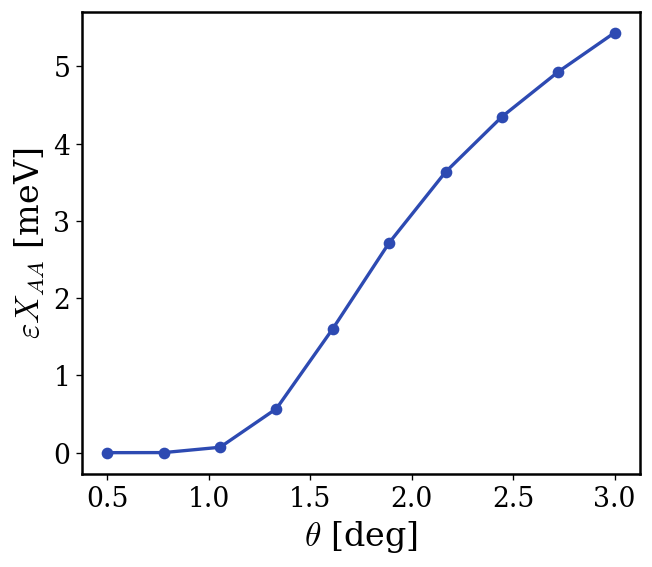

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, X, marker="o", label=r"$\varepsilon X$", color=cols[0])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon X_{AA}$ [meV]", fontsize=20)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


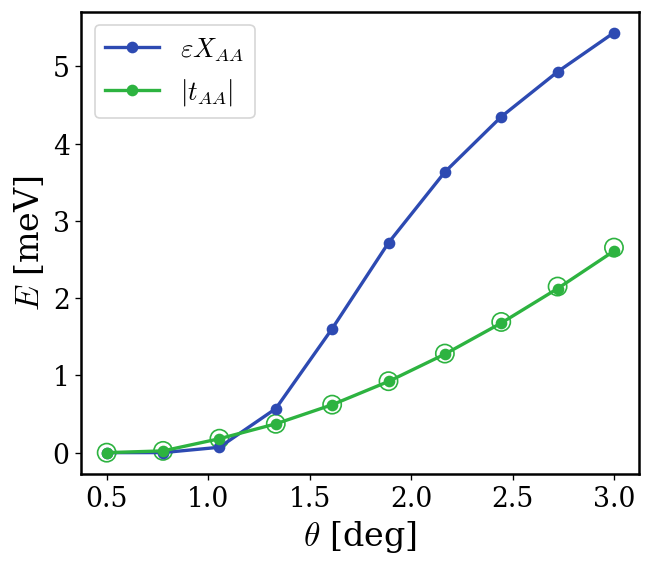

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, X, marker="o", label=r"$\varepsilon X_{AA}$", color=cols[0])
ax.plot(thetas, np.abs(tAA), marker="o", label=r"$|t_{AA}|$", color=cols[1])
ax.scatter(thetas, np.abs(tAA_kspace), marker="o", edgecolors=cols[1], facecolors="none", s=120)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$E$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Conditions

In [ ]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=40)
thetas = np.linspace(0.5, 3.0, 10)
UA = []
UA_kspace = []
UB = []
UB_kspace = []
Delta = []

tAB = []
tAA = []

for th in tqdm(thetas):
    sys.theta_deg = th

    interactionA = sys.interaction_2band(orders=[0], sublattice1="A", sublattice2="A")
    interactionB = sys.interaction_2band(orders=[0], sublattice1="B", sublattice2="B")
    hoppingsA_kspace = sys.hopping_2band_kspace(orders=[0], sublattice1="A", sublattice2="A")
    hoppingsB_kspace = sys.hopping_2band_kspace(orders=[0], sublattice1="B", sublattice2="B")
    interactionA_kspace = sys.interaction_2band_kspace(orders=[0], sublattice1="A", sublattice2="A")
    interactionB_kspace = sys.interaction_2band_kspace(orders=[0], sublattice1="B", sublattice2="B")

    # Coulomb matrix elements in eV
    UA.append(interactionA[0])
    UA_kspace.append(interactionA_kspace[0])
    UB.append(interactionB[0])
    UB_kspace.append(interactionB_kspace[0])
    Delta.append(hoppingsA_kspace[0] - hoppingsB_kspace[0])
    tAB.append(sys.hopping_2band_kspace(orders=[0], sublattice1="A", sublattice2="B")[0])
    tAA.append(sys.hopping_2band_kspace(orders=[1], sublattice1="A", sublattice2="A")[0])

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [04:21<00:00, 26.11s/it]


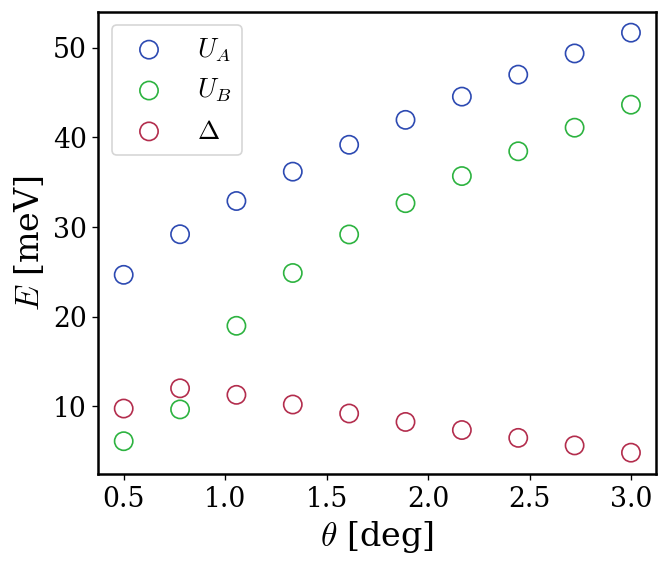

In [26]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

#ax.plot(thetas, UA, marker="o", label=r"$U_A$", color=cols[0])
ax.scatter(thetas, UA_kspace, marker="o", label=r"$U_A$", edgecolors=cols[0], facecolors="none", s=120)
#ax.plot(thetas, UB, marker="o", label=r"$U_B$", color=cols[1])
ax.scatter(thetas, UB_kspace, marker="o", label=r"$U_B$", edgecolors=cols[1], facecolors="none", s=120)
ax.scatter(thetas, Delta, marker="o", label=r"$\Delta$", edgecolors=cols[2], facecolors="none", s=120)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$E$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

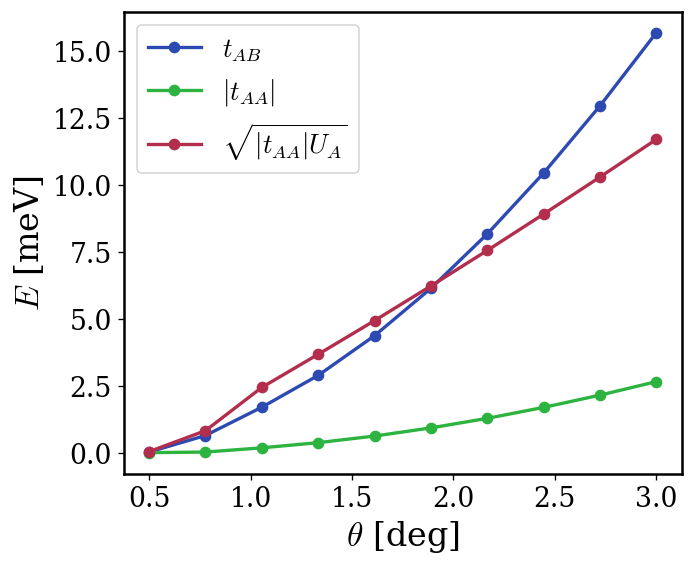

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, tAB, marker="o", label=r"$t_{AB }$", color=cols[0])
ax.plot(thetas, np.abs(tAA), marker="o", label=r"$|t_{AA }|$", color=cols[1])
ax.plot(thetas, np.sqrt(np.abs(tAA) * np.array(UA_kspace)), marker="o", label=r"$\sqrt{|t_{AA}|U_A}$", color=cols[2])

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$E$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

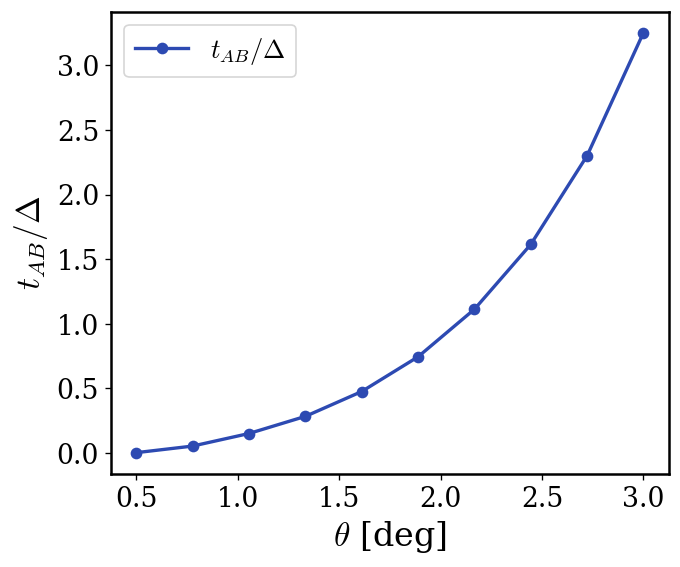

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, np.array(tAB) / np.array(Delta), marker="o", label=r"$t_{AB }/\Delta$", color=cols[0])

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t_{AB }/\Delta$", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Phase diagrams
### $(\theta,V)$

In [18]:
sys = HeteroBilayer(V=8, psi_deg=26)

THETA_MIN = 0.5
THETA_MAX = 1.5
THETA_POINTS = 10

V_MIN = 4.0
V_MAX = 10.0
V_POINTS = 10

thetas = np.linspace(THETA_MIN, THETA_MAX, THETA_POINTS)
V_vals = np.linspace(V_MIN, V_MAX, V_POINTS)

Thetamesh, Vmesh = np.meshgrid(thetas, V_vals)

J_vals = np.zeros((len(V_vals), len(thetas)))

for i, V in tqdm(enumerate(V_vals), total=len(V_vals)):
    sys.V = V
    for j, theta in enumerate(thetas):
        sys.theta_deg = theta
        J_vals[i, j] = sys.spin_coupling_2band()

  0%|          | 0/10 [00:00<?, ?it/s]

/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_56156/840440442.py:22: ComplexWarning: Casting complex values to real discards the imaginary part
  J_vals[i, j] = sys.spin_coupling_2band()
100%|██████████| 10/10 [31:00<00:00, 186.07s/it]


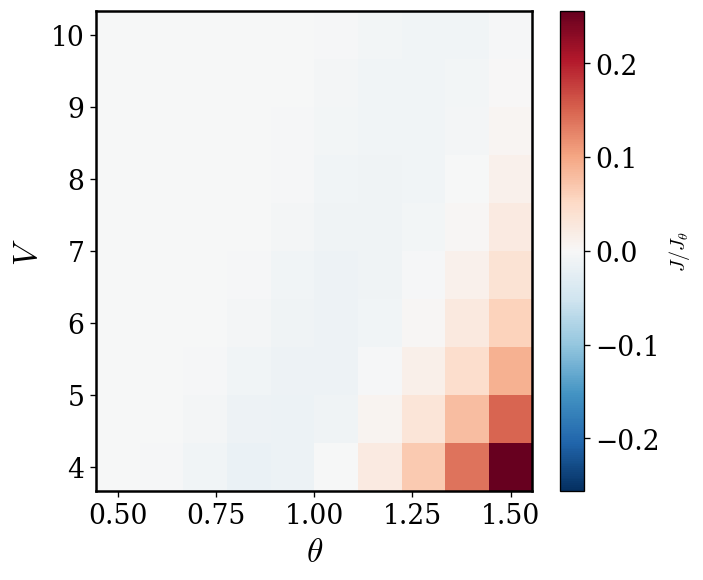

In [21]:
J_max = np.max(np.abs(J_vals))

plt.figure(figsize=(6, 5))

pcm = plt.pcolormesh(
    Thetamesh, Vmesh, J_vals,
    shading="auto",
    cmap="RdBu_r",
    vmin=-J_max,
    vmax=J_max,
)

plt.colorbar(pcm, label=r"$J / J_\theta$")
plt.xlabel(r"$\theta$", fontsize=20)
plt.ylabel(r"$V$", fontsize=20)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")
plt.tight_layout()
plt.show()

### $(\theta,\varepsilon^{-1})$

In [29]:
sys = HeteroBilayer(psi_deg=40)

THETA_MIN = 0.5
THETA_MAX = 1.5
THETA_POINTS = 10

EPS_MIN = 0.04
EPS_MAX = 0.1
EPS_POINTS = 10

thetas = np.linspace(THETA_MIN, THETA_MAX, THETA_POINTS)
inv_epsilon = np.linspace(EPS_MIN, EPS_MAX, EPS_POINTS)

Thetamesh, Eps_mesh = np.meshgrid(thetas, inv_epsilon)

J_vals = np.zeros((len(inv_epsilon), len(thetas)))

for i, ie in tqdm(enumerate(inv_epsilon), total=len(inv_epsilon)):
    sys.epsilon = 1 / ie
    for j, theta in enumerate(thetas):
        sys.theta_deg = theta
        J_vals[i, j] = sys.spin_coupling_2band()

  0%|          | 0/10 [00:00<?, ?it/s]

/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_24377/3758537625.py:22: ComplexWarning: Casting complex values to real discards the imaginary part
  J_vals[i, j] = sys.spin_coupling_2band()
100%|██████████| 10/10 [35:31<00:00, 213.12s/it]


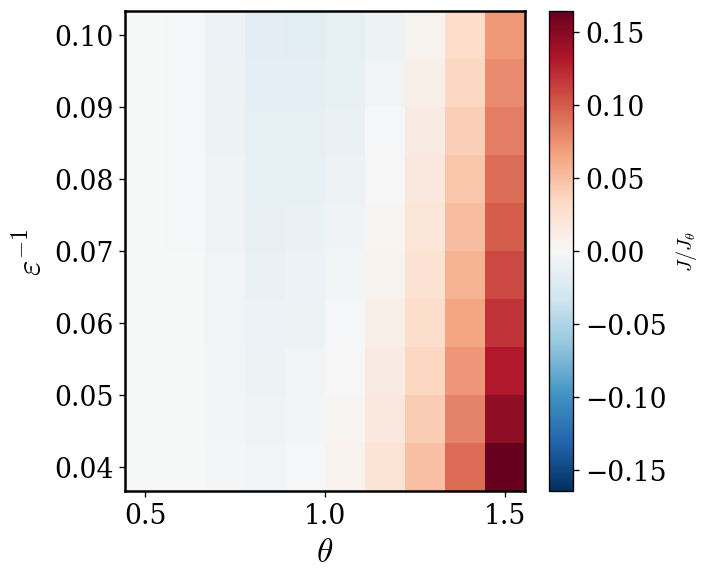

In [30]:
J_max = np.max(np.abs(J_vals))

plt.figure(figsize=(6, 5))

pcm = plt.pcolormesh(
    Thetamesh, Eps_mesh, J_vals,
    shading="auto",
    cmap="RdBu_r",
    vmin=-J_max,
    vmax=J_max,
)

plt.colorbar(pcm, label=r"$J / J_\theta$")
plt.xlabel(r"$\theta$", fontsize=20)
plt.ylabel(r"$\varepsilon^{-1}$", fontsize=20)

# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.tight_layout()
plt.show()